In [1]:
from anemone.forwards import Forward
from anemone.inversion import Inversion, ColeCole
import torch
from anemone.system import *
import matplotlib.pyplot as plt
import numpy as np

In [2]:
tx = Loop.square(40)
rx = Receiver()
times = torch.logspace(-6, -3, 32)

fwr = Forward.colecole(tx, rx, times)

C:\Users\au646858\OneDrive - Aarhus Universitet\Documents\_repositories\anemone\src\anemone\transforms\transforms.py:345: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4424.)
  return func(lamda/c.sqrt_twopi).T/torch.sqrt(lamda)


In [3]:
o31 = torch.ones(31)
cole = ColeCole.smooth([o31*100., o31*1e-1, o31*10., o31*3.], torch.logspace(0,1, 30).cumsum(0))

In [4]:
dbdt = fwr(*cole.mod)

C:\Users\au646858\OneDrive - Aarhus Universitet\Documents\_repositories\anemone\src\anemone\forwards\forwards.py:853: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Copy.cpp:307.)
  cRTE = rte(self.sigma, self.thick, self.omega, self.lamda).squeeze().to(rdtype)


In [5]:
inv = Inversion(dbdt, dbdt*0.03, cole.copy(), fwr)
inv.setup_matrices()
G = inv.jacobian(inv.m)

In [6]:
from anemone.physics import drte_dsigma

In [7]:
dbdt = fwr(*cole.mod)
rho,m,tau,c,thick = cole.mod
w = fwr.omega

In [24]:
drds = drte_dsigma(fwr.sigma, fwr.thick, fwr.omega, fwr.lamda)
drdrho = - drds / rho[None,:]**2

In [25]:
iwtp1 = 1+1j*w[:,None]*tau[None,:]
drhodm = -rho*(1-iwtp1**(-c[None,:]))
drhodt = -c*rho[None,:]*m[None,:]*(iwtp1**(-c-1))*(1j*w[:,None])
drhodc = -rho[None,:]*m[None,:]*torch.log(iwtp1)*(iwtp1**(-c[None,:]))

In [26]:
Gana = torch.pi*4e-7*fwr.H2t @ torch.concatenate([drdrho, drdrho*drhodm, drdrho*drhodt, drdrho*drhodc], dim=1).real

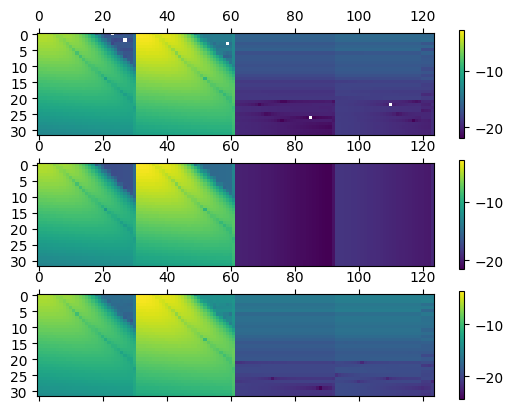

In [27]:
fig,axs = plt.subplots(3,1)
plt.colorbar(axs[0].matshow(G.abs().log10()), ax=axs[0])
plt.colorbar(axs[1].matshow(Gana.abs().log10()), ax=axs[1])
plt.colorbar(axs[2].matshow((G-Gana).abs().log10()), ax=axs[2])

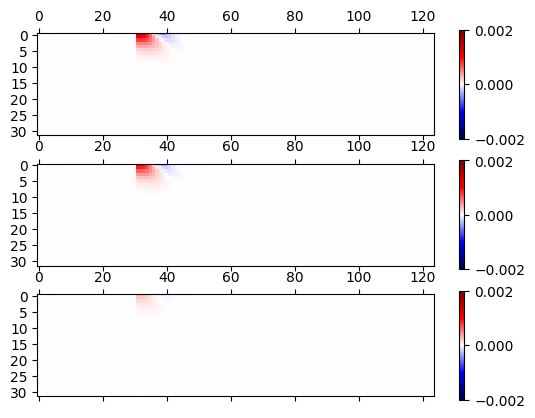

In [28]:
fig,axs = plt.subplots(3,1)
plt.colorbar(axs[0].matshow(G, vmin=-0.002, vmax=0.002, cmap='seismic'), ax=axs[0])
plt.colorbar(axs[1].matshow(Gana, vmin=-0.002, vmax=0.002, cmap='seismic'), ax=axs[1])
plt.colorbar(axs[2].matshow((G-Gana), vmin=-0.002, vmax=0.002, cmap='seismic'), ax=axs[2])

C:\Users\au646858\AppData\Local\Temp\ipykernel_17692\440296174.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  plt.colorbar(axs[0].matshow(np.sign(G), cmap='seismic'), ax=axs[0])
C:\Users\au646858\AppData\Local\Temp\ipykernel_17692\440296174.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  plt.colorbar(axs[1].matshow(np.sign(Gana), cmap='seismic'), ax=axs[1])
C:\Users\au646858\AppData\Local\Temp\ipykernel_17692\440296174.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  plt.colorbar(axs[2].matshow(np.sign(G-Gana), cmap='seismic'), ax=axs[2])


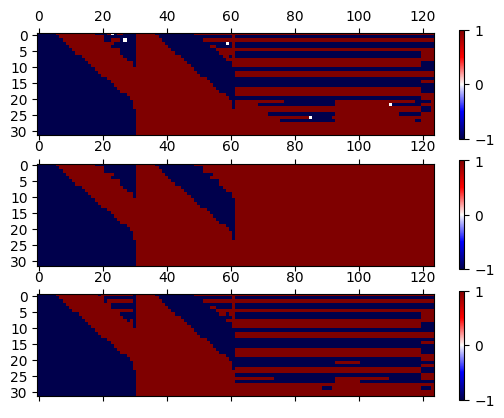

In [29]:
fig,axs = plt.subplots(3,1)
plt.colorbar(axs[0].matshow(np.sign(G), cmap='seismic'), ax=axs[0])
plt.colorbar(axs[1].matshow(np.sign(Gana), cmap='seismic'), ax=axs[1])
plt.colorbar(axs[2].matshow(np.sign(G-Gana), cmap='seismic'), ax=axs[2])

ValueError: supplied range of [-inf, inf] is not finite

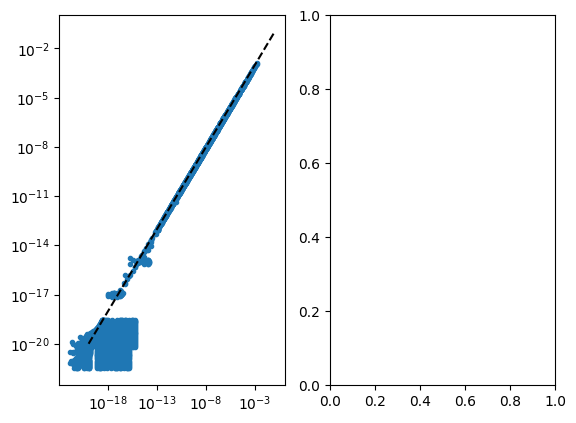

In [162]:
fig,axs = plt.subplots(1,2)
axs[0].loglog(G.flatten().abs(), Gana.flatten().abs(), '.')
axs[0].loglog([1e-20, 1e-1], [1e-20, 1e-1], 'k--')
axs[1].hist(Gana.flatten()/G.flatten(), bins=50)


In [ ]:
ln_fwr = Forward.colecole(tx, rx, times, log_scale=True)
o31 = torch.ones(31)
ln_cole = ColeCole.smooth([o31*100., o31*1e-1, o31*10., o31*3.], torch.logspace(0,1, 30).cumsum(0), log_scale=True)

inv = Inversion(dbdt.log(), torch.log1p(dbdt*0+0.03), ln_cole.copy(), ln_fwr)
inv.setup_matrices()

In [137]:
ln_G = inv.jacobian(inv.m)

In [139]:
ln_Gana = Gana/dbdt[:, None]
ln_Gana *= torch.concatenate([rho, m, tau, c], dim=0)[None,:]

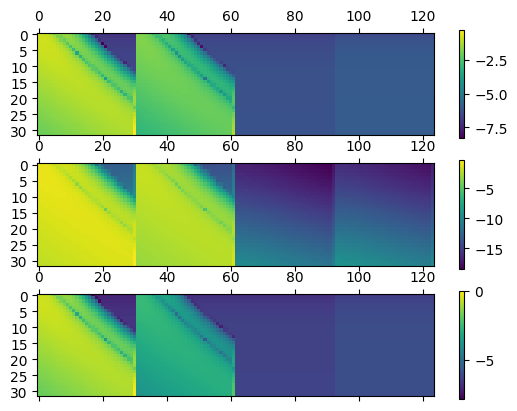

In [140]:
fig,axs = plt.subplots(3,1)
plt.colorbar(axs[0].matshow(ln_G.abs().log10()), ax=axs[0])
plt.colorbar(axs[1].matshow(ln_Gana.abs().log10()), ax=axs[1])
plt.colorbar(axs[2].matshow((ln_G-ln_Gana).abs().log10()), ax=axs[2])

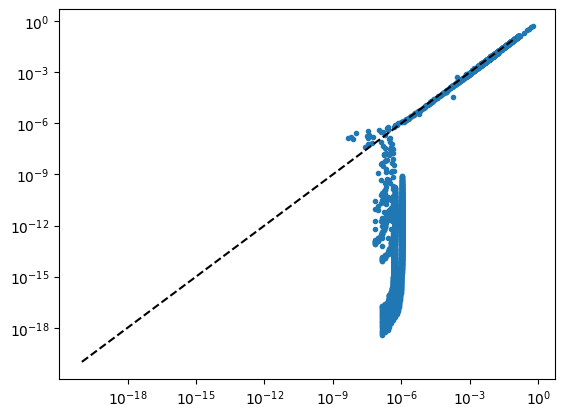

In [141]:
plt.figure()
plt.loglog(ln_G.flatten().abs(), ln_Gana.flatten().abs(), '.')
plt.loglog([1e-20, 1e-1], [1e-20, 1e-1], 'k--')